# 02 · EDA, regímenes y análisis de features

Notebook de demostración de la parte 02 (`code/evaluate.py`, `code/plots.py`). Solo importa funciones y muestra los artefactos de
`python main.py`. Todo usa únicamente datos de entrenamiento. Guía: `docs/instrucciones/02_eda_features.md`.

In [1]:
import sys
sys.path.insert(0, "..")
sys.modules.pop("code", None)  # IPython ya importó el módulo `code` estándar (ver docs/decisiones.md)

import pandas as pd
from IPython.display import Image

from code import data, evaluate
from main import ARTIFACTS, BTC_CSV, FIGURES, FOLDS

ohlcv, _ = data.load_ohlcv(BTC_CSV)
features = data.compute_features(ohlcv)
train_ohlcv, train_features = evaluate.train_frames(ohlcv, features, FOLDS[1])

## 1. Regímenes (pregunta 1)

Giros de 45 % en el cierre diario. Se conocen después de ocurrir: describen el train y no entran al estado.

In [2]:
regimes = pd.read_csv(ARTIFACTS / "regimes.csv", parse_dates=["start", "end"])
regimes[regimes["fold"] == 1].drop(columns="fold").round(2)

/var/folders/20/xvvxf3fd0bsc8mhjgvpylzzc0000gn/T/ipykernel_20808/1809647228.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  regimes[regimes["fold"] == 1].drop(columns="fold").round(2)


,regime,start,end,days,direction,total_return,annual_trend_log,annual_volatility,max_drawdown,status,volatility_level
0,1,2017-08-17 00:00:00+00:00,2017-09-14 00:00:00+00:00,28,baja,-0.26,-3.85,1.08,-0.34,incompleto,alta
1,2,2017-09-14 00:00:00+00:00,2017-12-16 00:00:00+00:00,93,alza,4.99,7.03,0.97,-0.21,completo,alta
2,3,2017-12-16 00:00:00+00:00,2018-12-15 00:00:00+00:00,364,baja,-0.83,-1.79,0.87,-0.83,completo,baja
3,4,2018-12-15 00:00:00+00:00,2019-06-26 00:00:00+00:00,193,alza,3.08,2.66,0.64,-0.16,completo,baja
4,5,2019-06-26 00:00:00+00:00,2020-03-12 00:00:00+00:00,260,baja,-0.63,-1.41,0.91,-0.63,completo,alta
5,6,2020-03-12 00:00:00+00:00,2021-04-13 00:00:00+00:00,397,alza,12.24,2.38,0.71,-0.25,completo,baja
6,7,2021-04-13 00:00:00+00:00,2021-07-20 00:00:00+00:00,98,baja,-0.53,-2.82,0.92,-0.53,completo,alta
7,8,2021-07-20 00:00:00+00:00,2021-12-31 00:00:00+00:00,164,alza,0.55,0.98,0.67,-0.32,incompleto,baja


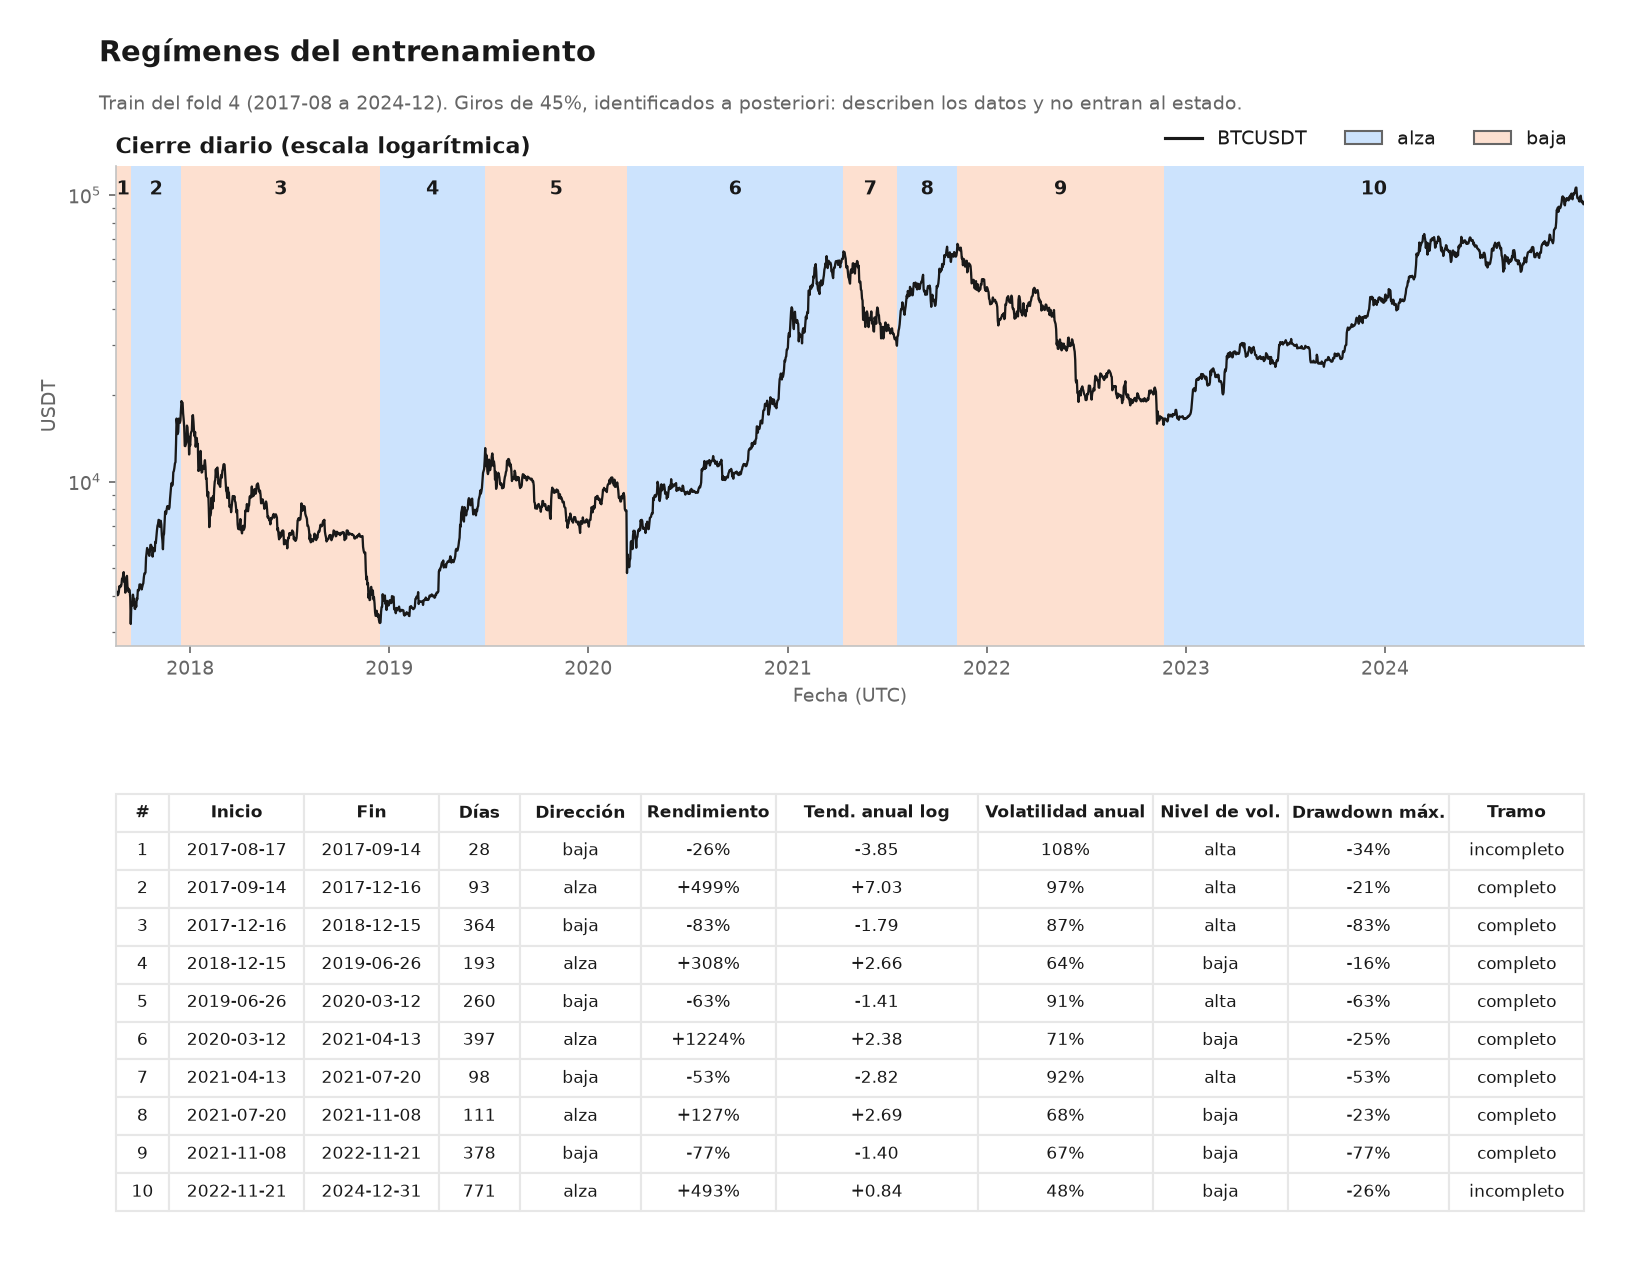

In [3]:
Image(FIGURES / "eda_regimenes.png", width=900)

## 2. Distribución y autocorrelación

Colas pesadas y volatilidad agrupada; los rendimientos casi no se predicen a sí mismos.

In [4]:
hourly = evaluate.hourly_returns(train_ohlcv)
print(evaluate.distribution_stats(hourly).round(4))
evaluate.ljung_box_table(hourly).round(4)

n                  3.819400e+04
mean               1.000000e-04
std                9.500000e-03
skew              -4.828000e-01
excess_kurtosis    2.976000e+01
jarque_bera        1.410934e+06
jarque_bera_p      0.000000e+00
min               -2.010000e-01
max                1.603000e-01
dtype: float64


,series,lags,acf_1,statistic,p_value
0,rendimientos,24,-0.0528,347.8703,0.0
1,rendimientos,168,-0.0528,711.5127,0.0
2,absolutos,24,0.3001,51474.5808,0.0
3,absolutos,168,0.3001,181315.4059,0.0
4,cuadrados,24,0.1754,12669.4783,0.0
5,cuadrados,168,0.1754,22200.8887,0.0


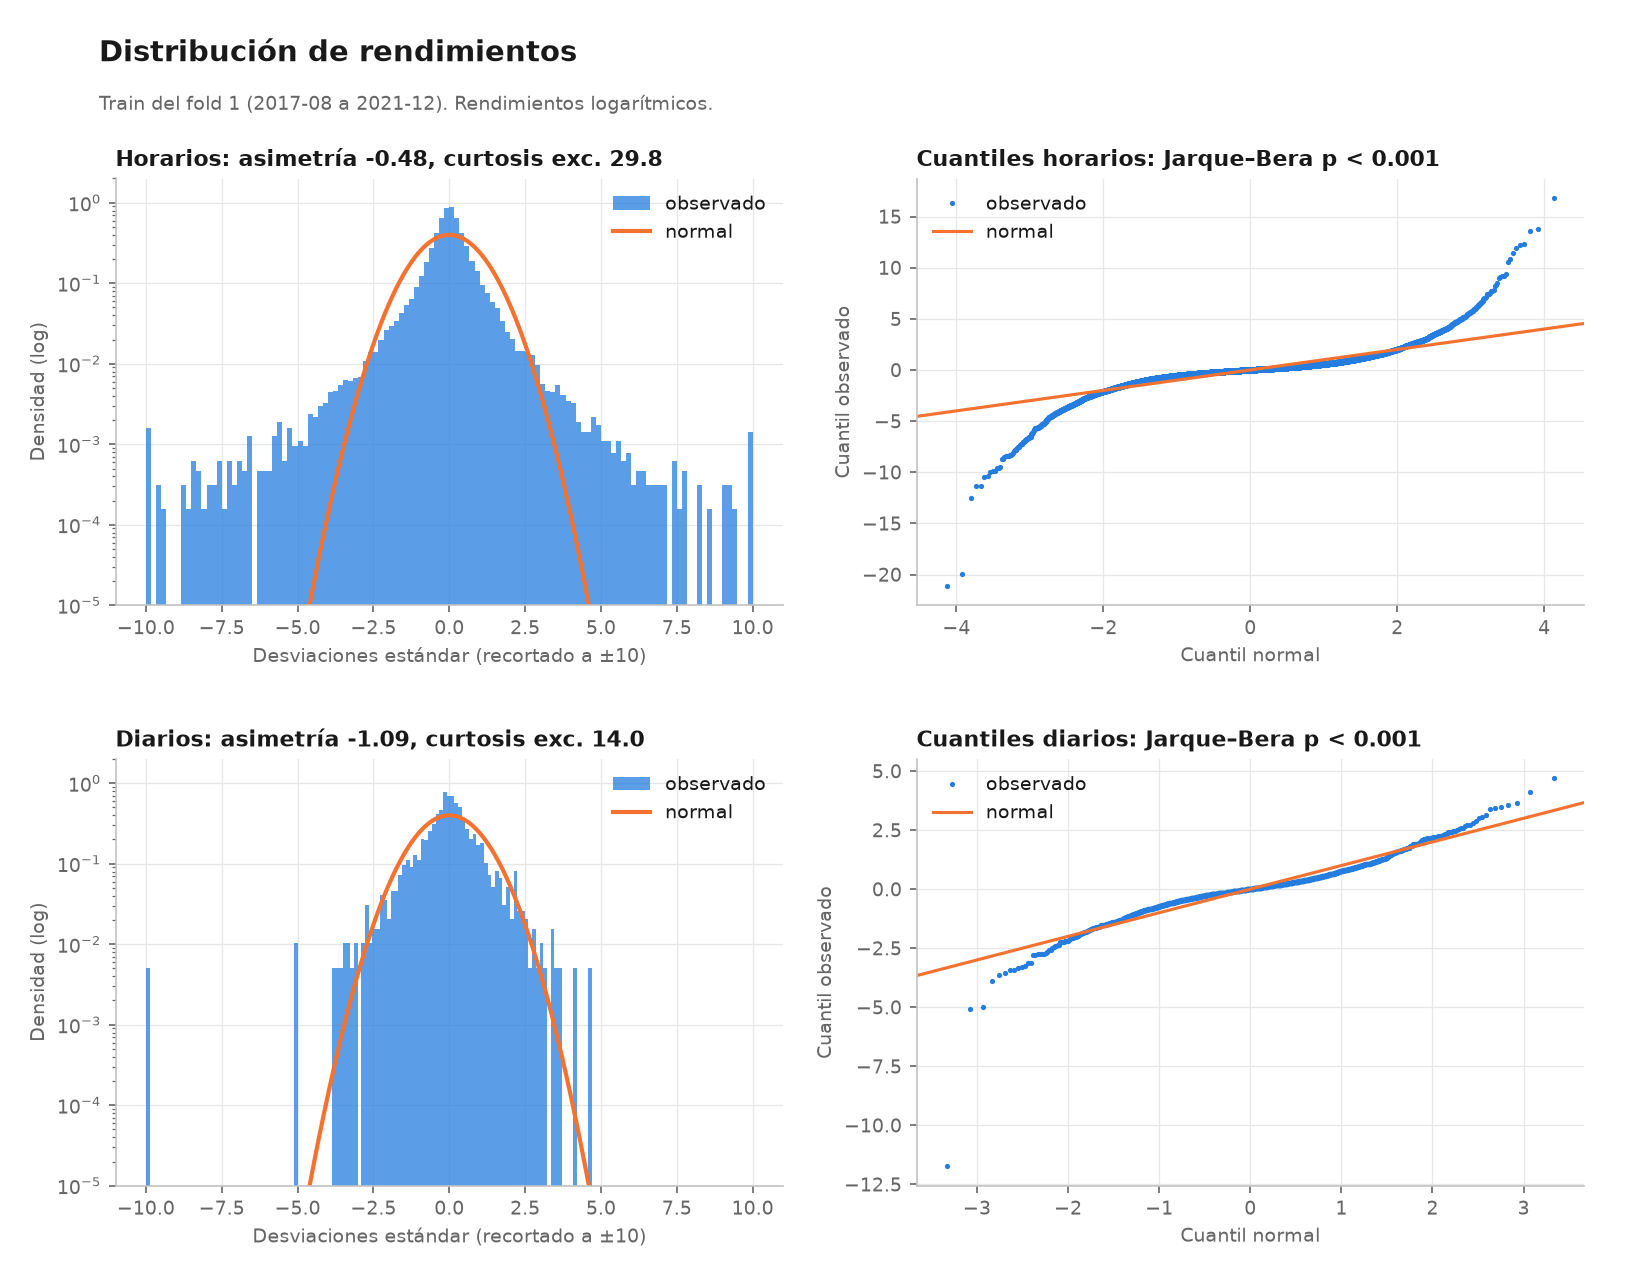

In [5]:
Image(FIGURES / "eda_distribucion.png", width=900)

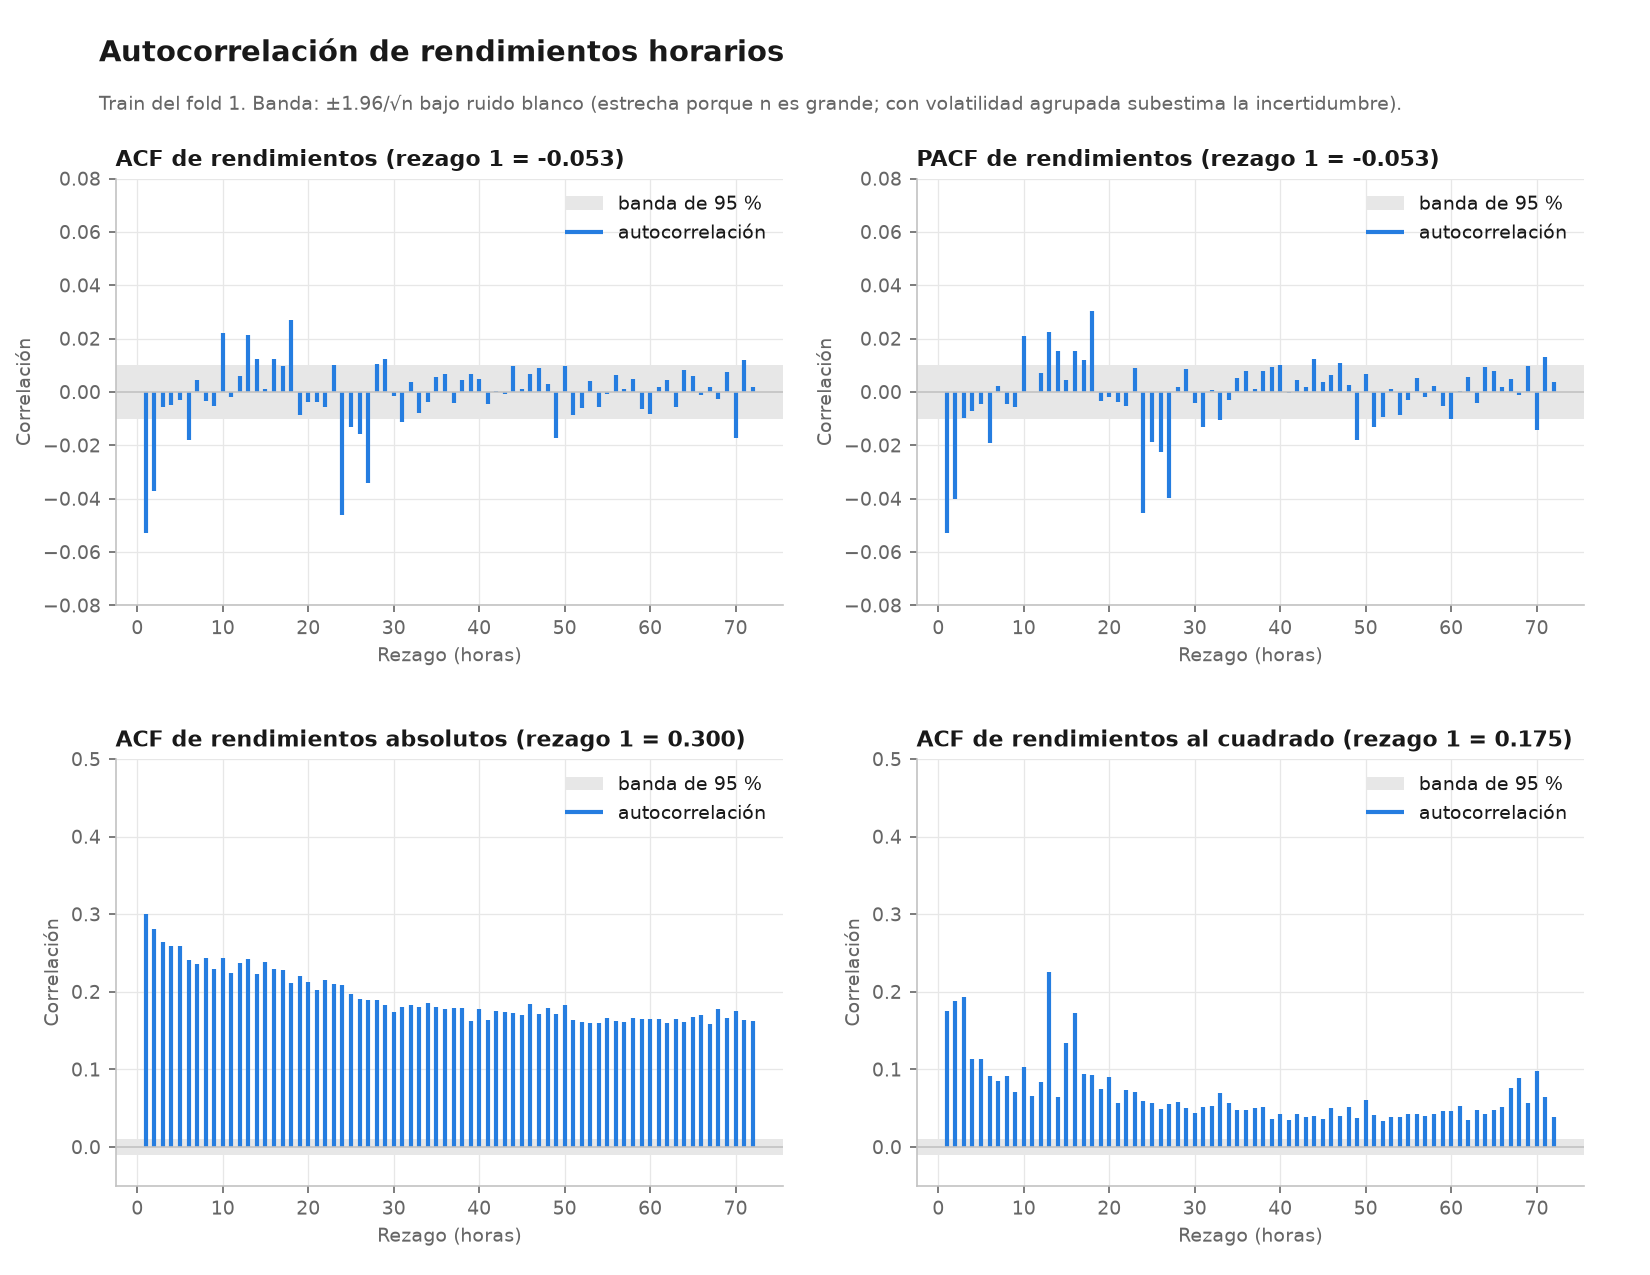

In [6]:
Image(FIGURES / "eda_autocorrelacion.png", width=900)

## 3. Estacionariedad

El log-precio tiene raíz unitaria; por eso el estado usa rendimientos y razones, no precios.

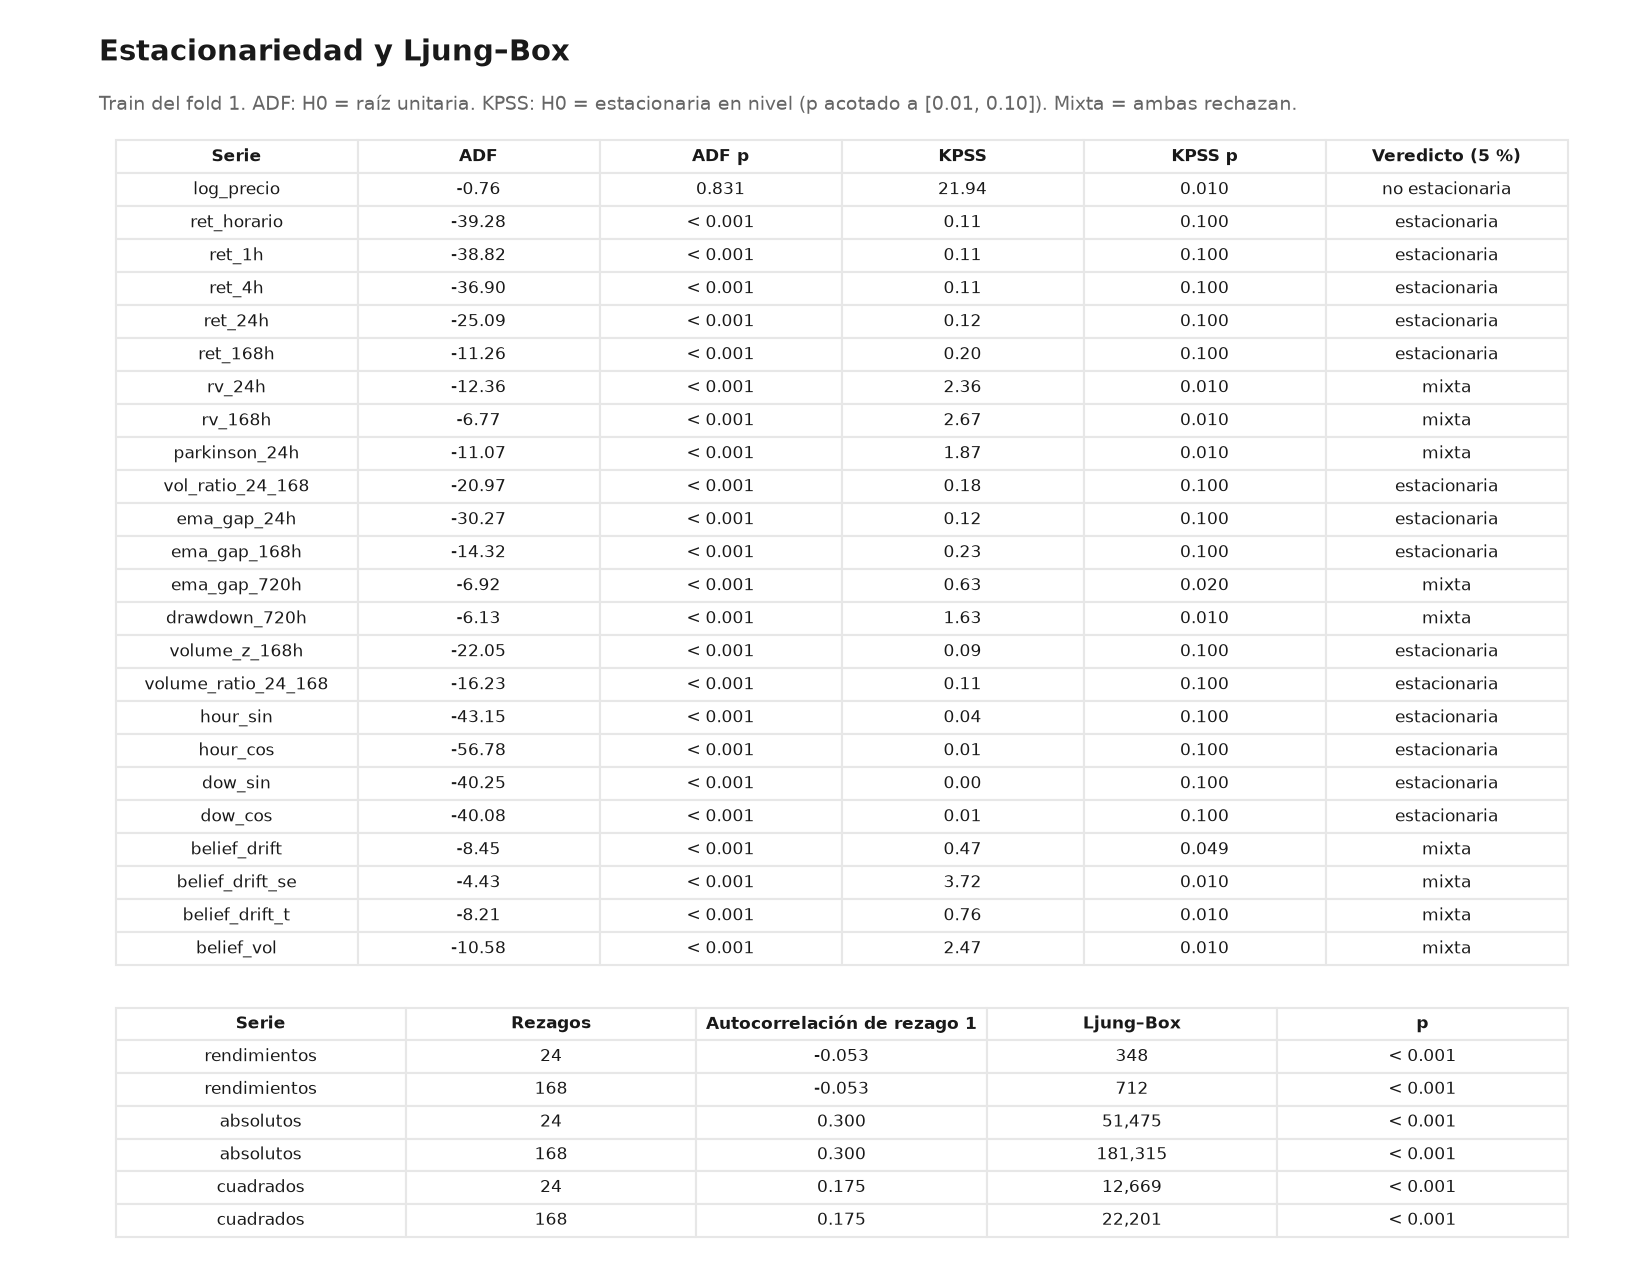

In [7]:
Image(FIGURES / "eda_estacionariedad.png", width=900)

## 4. Features contra el rendimiento a 24 h (pregunta 2)

Muestra sin traslape en una malla de horas de reloj (cada 25 h desde el inicio del train; aquí, desfase 0). La información es sobre todo del tamaño del movimiento, no de su dirección.

In [8]:
cols = ["family", "mi", "mi_p", "mi_null_max_95", "mi_all_hours", "spearman", "spearman_abs_target", "verdict"]
pd.read_csv(ARTIFACTS / "feature_analysis_fold_1.csv", index_col=0)[cols].sort_values("mi", ascending=False).round(3)

,family,mi,mi_p,mi_null_max_95,mi_all_hours,spearman,spearman_abs_target,verdict
feature,,,,,,,,
parkinson_24h,volatility,0.056,0.005,0.056,0.104,0.016,0.294,mixta
belief_drift_se,belief,0.052,0.020,0.056,0.183,0.027,0.330,mixta
belief_vol,belief,0.052,0.010,0.056,0.091,0.016,0.300,mixta
rv_24h,volatility,0.044,0.020,0.056,0.108,0.018,0.272,mixta
belief_drift,belief,0.043,0.020,0.056,0.085,0.040,-0.017,mixta
rv_168h,volatility,0.041,0.020,0.056,0.179,0.018,0.325,mixta
drawdown_720h,trend,0.037,0.040,0.056,0.096,0.035,-0.130,mixta
ema_gap_24h,trend,0.031,0.055,0.056,0.039,0.028,-0.022,estacionaria
ema_gap_168h,trend,0.025,0.075,0.056,0.051,0.018,-0.033,estacionaria


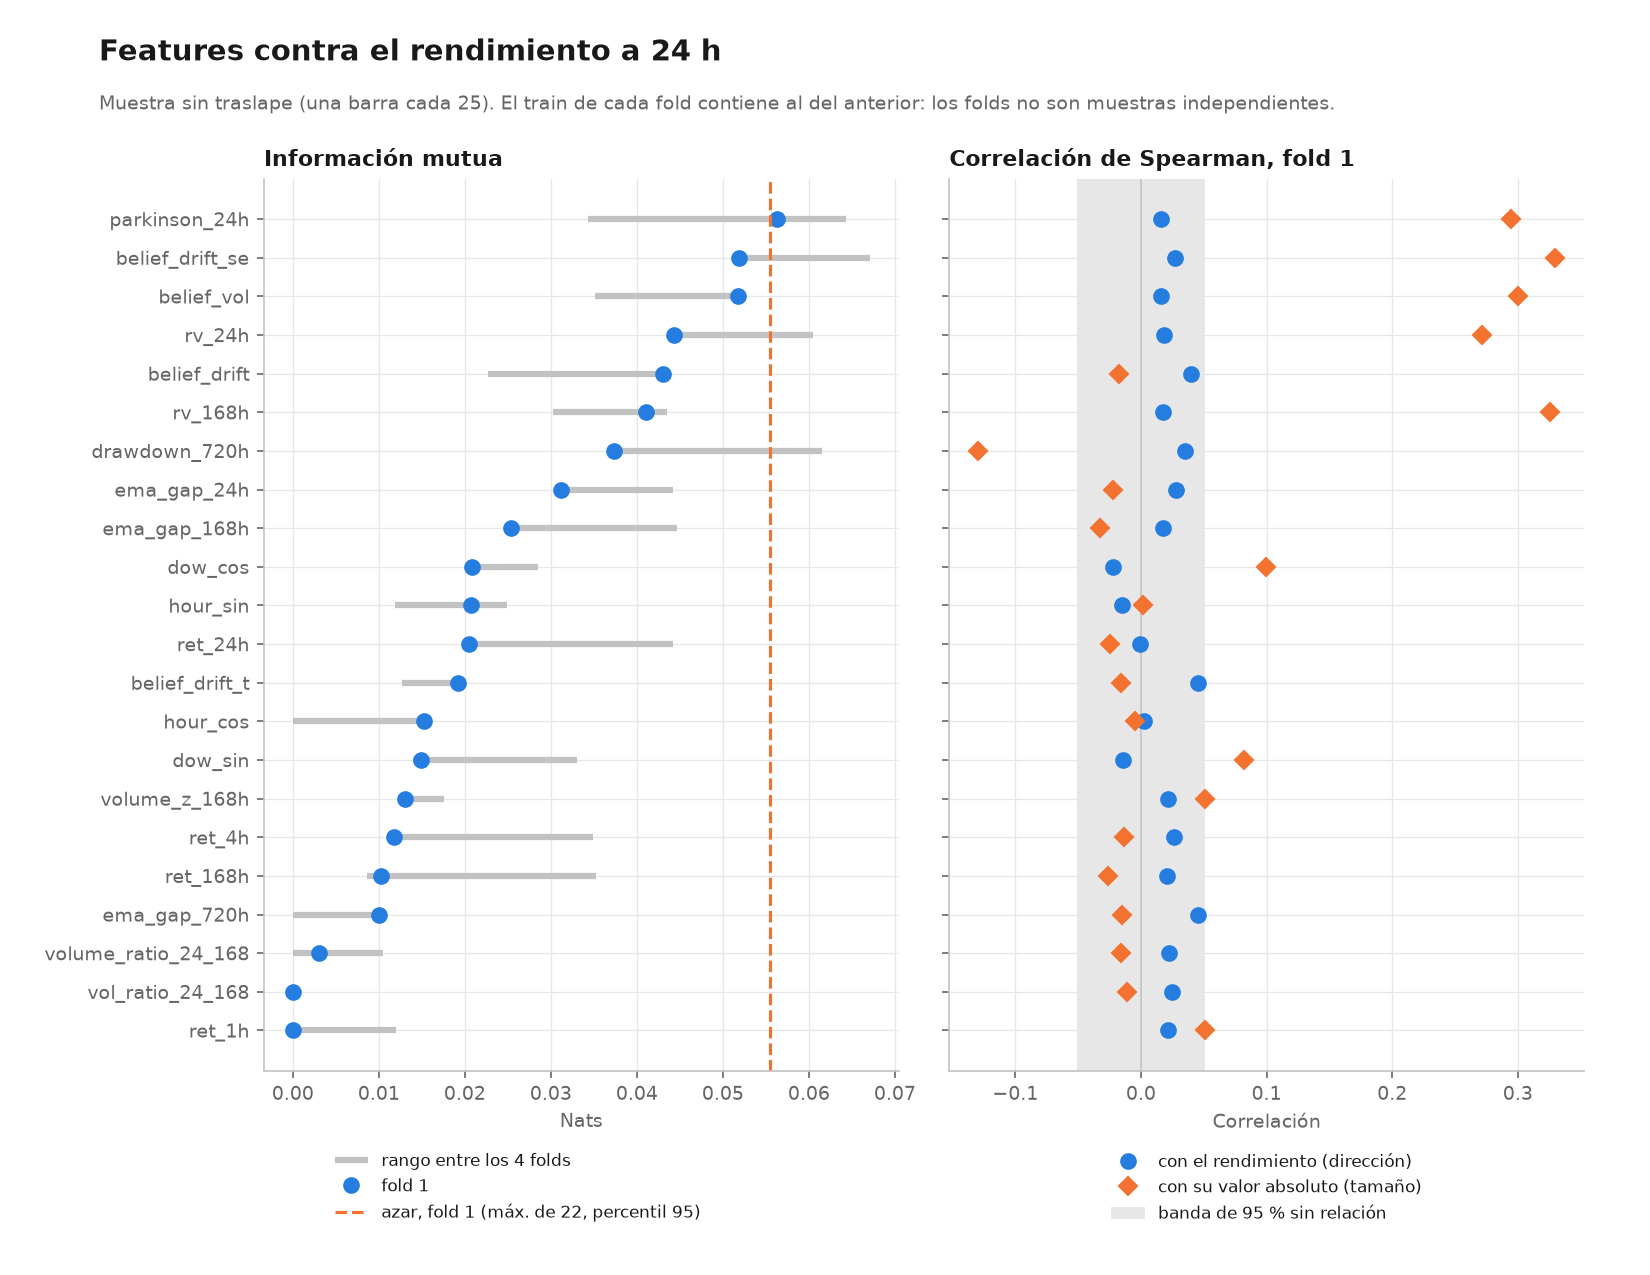

In [9]:
Image(FIGURES / "eda_features.png", width=900)

**Estabilidad entre folds:** en cuántos folds supera cada feature el nivel de azar (desfase 0).

In [10]:
folds = {k: pd.read_csv(ARTIFACTS / f"feature_analysis_fold_{k}.csv", index_col=0) for k in FOLDS}
pd.DataFrame({k: t["mi"] > t["mi_null_max_95"] for k, t in folds.items()}).sum(axis=1).sort_values(ascending=False).rename("folds")

feature
rv_24h                 3
belief_drift_se        3
parkinson_24h          3
drawdown_720h          1
belief_vol             1
rv_168h                0
hour_sin               0
belief_drift_t         0
ret_24h                0
belief_drift           0
dow_cos                0
dow_sin                0
hour_cos               0
volume_ratio_24_168    0
ret_168h               0
volume_z_168h          0
ret_4h                 0
ema_gap_720h           0
ema_gap_168h           0
ema_gap_24h            0
vol_ratio_24_168       0
ret_1h                 0
Name: folds, dtype: int64

## 5. Robustez a la fase de la malla

El mismo análisis en los 25 desfases de la malla: en cuántos supera cada feature el azar (IM) y en cuántos tiene p < 0.05 con la dirección y con el tamaño. Por azar se esperan ≈ 1.2 de 25 con p < 0.05. El tamaño es estable; la dirección, no.

In [11]:
robust = {k: pd.read_csv(ARTIFACTS / f"feature_robustness_fold_{k}.csv", index_col=0) for k in FOLDS}
cols = ["mi_median", "mi_above_null", "spearman_median", "spearman_sig", "spearman_abs_sig"]
robust[1][cols].sort_values(["mi_above_null", "spearman_abs_sig"], ascending=False).round(3)

,mi_median,mi_above_null,spearman_median,spearman_sig,spearman_abs_sig
feature,,,,,
belief_drift_se,0.062,21,0.025,0,25
rv_168h,0.055,15,0.017,0,25
belief_vol,0.052,14,0.017,0,25
rv_24h,0.051,11,0.018,0,25
parkinson_24h,0.042,9,0.023,0,25
drawdown_720h,0.034,4,0.040,2,25
ema_gap_24h,0.020,3,-0.029,5,2
ret_168h,0.030,3,0.028,2,0
ret_4h,0.018,2,-0.016,4,3


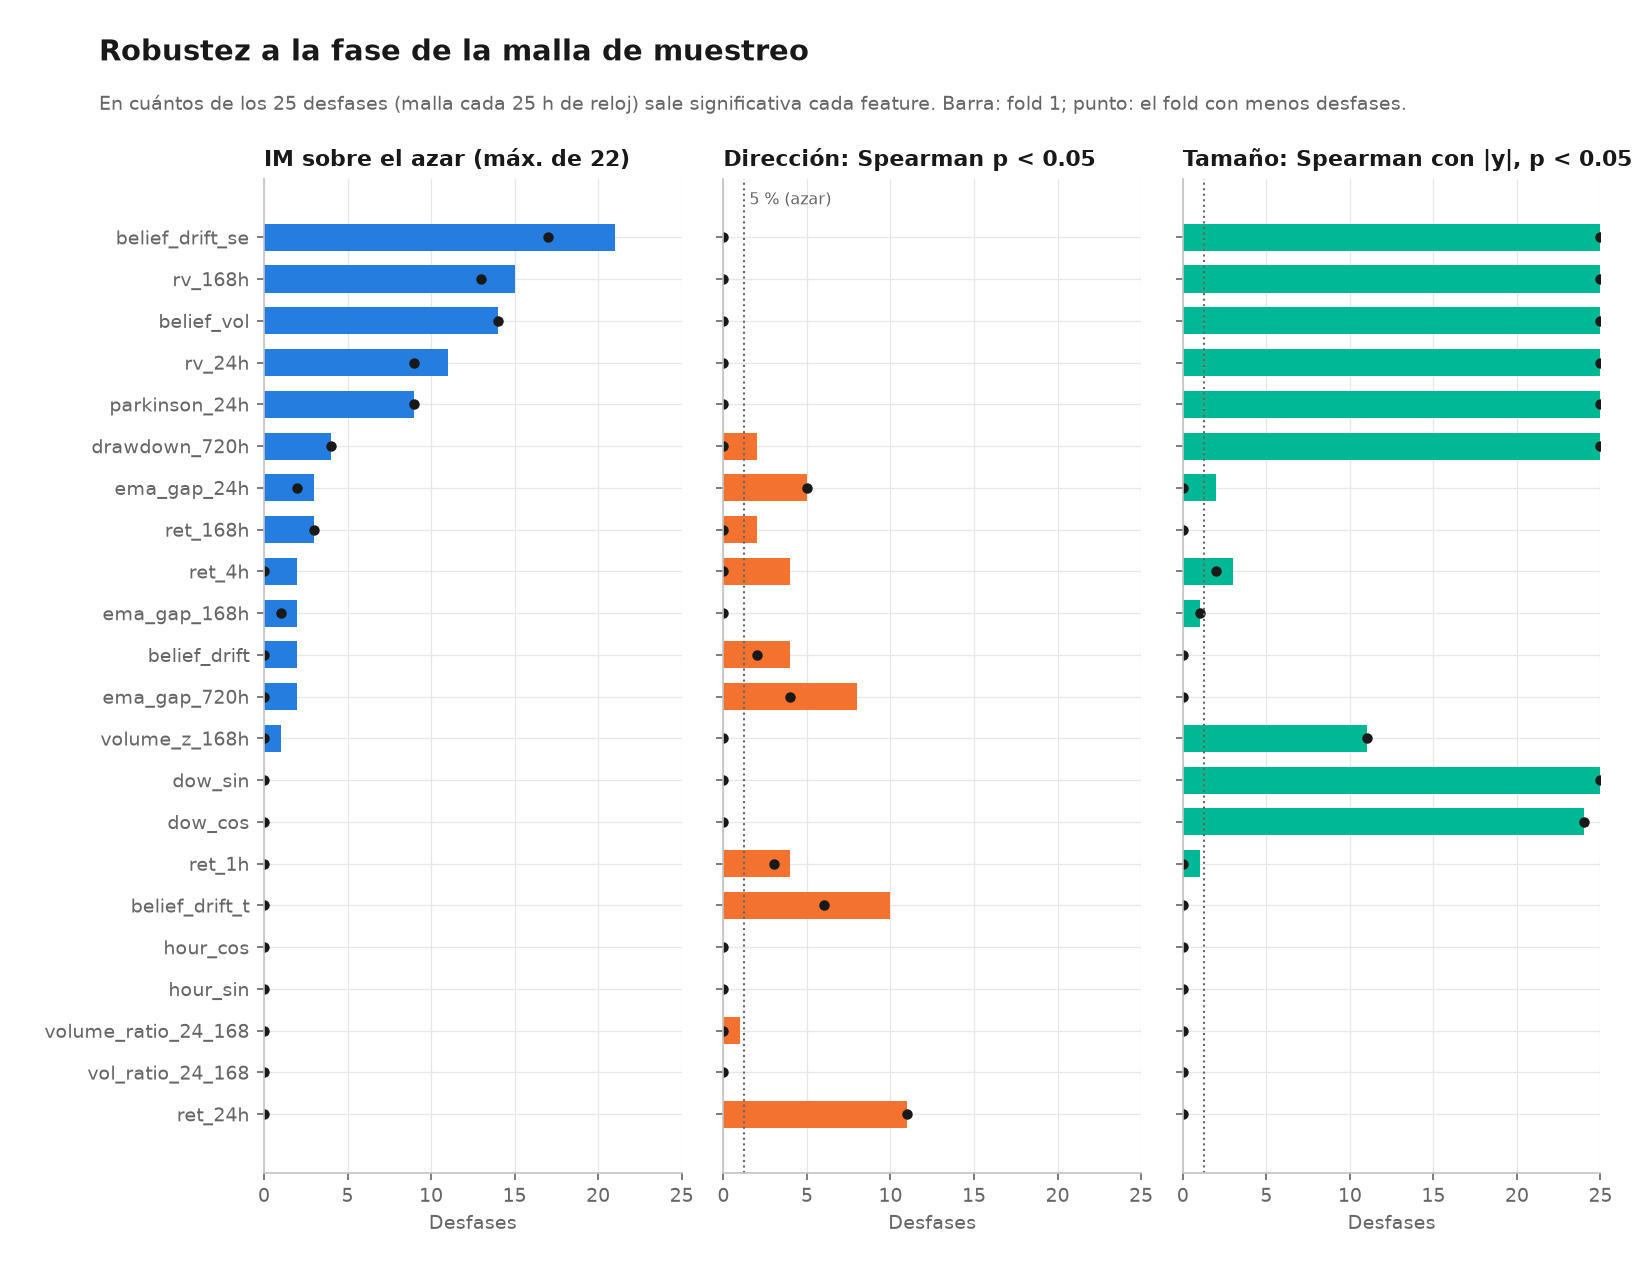

In [12]:
Image(FIGURES / "eda_robustez.png", width=900)